# Proyek Analisis Data: Kualitas Udara Beijing (PRSA)

- **Nama:** Retno Eka Triatry
- **Dataset:** Beijing Multi-Site Air-Quality Data (12 stasiun pemantau, 1 Maret 2013 – 28 Februari 2017)

## Menentukan Pertanyaan Bisnis

1. Bagaimana tren dan pola musiman konsentrasi PM2.5 selama 2013–2017, dan stasiun mana yang paling tercemar?
2. Faktor cuaca apa (suhu, tekanan, titik embun, curah hujan, kecepatan dan arah angin) yang paling berkaitan dengan tinggi-rendahnya PM2.5?

## Import Semua Packages/Library yang Digunakan

In [1]:
import glob

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

## Data Wrangling

### Gathering Data

In [2]:
files = sorted(glob.glob("data/PRSA_Data_*.csv"))
print(f"Jumlah file: {len(files)}")
raw_df = pd.concat([pd.read_csv(f) for f in files], ignore_index=True)
raw_df.head()

Jumlah file: 12


,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,wd,WSPM,station
0,1,2013,3,1,0,4.0,4.0,4.0,7.0,300.0,77.0,-0.7,1023.0,-18.8,0.0,NNW,4.4,Aotizhongxin
1,2,2013,3,1,1,8.0,8.0,4.0,7.0,300.0,77.0,-1.1,1023.2,-18.2,0.0,N,4.7,Aotizhongxin
2,3,2013,3,1,2,7.0,7.0,5.0,10.0,300.0,73.0,-1.1,1023.5,-18.2,0.0,NNW,5.6,Aotizhongxin
3,4,2013,3,1,3,6.0,6.0,11.0,11.0,300.0,72.0,-1.4,1024.5,-19.4,0.0,NW,3.1,Aotizhongxin
4,5,2013,3,1,4,3.0,3.0,12.0,12.0,300.0,72.0,-2.0,1025.2,-19.5,0.0,N,2.0,Aotizhongxin


**Insight:**
- Dataset terdiri dari 12 file CSV (satu per stasiun) dengan struktur kolom yang sama, sehingga bisa langsung digabung.
- Setiap baris adalah pengukuran per jam: polutan (PM2.5, PM10, SO2, NO2, CO, O3) dan cuaca (TEMP, PRES, DEWP, RAIN, wd, WSPM).

### Assessing Data

In [3]:
raw_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 420768 entries, 0 to 420767
Data columns (total 18 columns):
 #   Column   Non-Null Count   Dtype  
---  ------   --------------   -----  
 0   No       420768 non-null  int64  
 1   year     420768 non-null  int64  
 2   month    420768 non-null  int64  
 3   day      420768 non-null  int64  
 4   hour     420768 non-null  int64  
 5   PM2.5    412029 non-null  float64
 6   PM10     414319 non-null  float64
 7   SO2      411747 non-null  float64
 8   NO2      408652 non-null  float64
 9   CO       400067 non-null  float64
 10  O3       407491 non-null  float64
 11  TEMP     420370 non-null  float64
 12  PRES     420375 non-null  float64
 13  DEWP     420365 non-null  float64
 14  RAIN     420378 non-null  float64
 15  wd       418946 non-null  object 
 16  WSPM     420450 non-null  float64
 17  station  420768 non-null  object 
dtypes: float64(11), int64(5), object(2)
memory usage: 57.8+ MB


In [4]:
print("Missing value per kolom:")
print(raw_df.isna().sum())
print("\nBaris duplikat:", raw_df.duplicated().sum())
print("Baris per stasiun:")
print(raw_df["station"].value_counts())

Missing value per kolom:
No             0
year           0
month          0
day            0
hour           0
PM2.5       8739
PM10        6449
SO2         9021
NO2        12116
CO         20701
O3         13277
TEMP         398
PRES         393
DEWP         403
RAIN         390
wd          1822
WSPM         318
station        0
dtype: int64



Baris duplikat: 0
Baris per stasiun:
station
Aotizhongxin     35064
Changping        35064
Dingling         35064
Dongsi           35064
Guanyuan         35064
Gucheng          35064
Huairou          35064
Nongzhanguan     35064
Shunyi           35064
Tiantan          35064
Wanliu           35064
Wanshouxigong    35064
Name: count, dtype: int64


In [5]:
raw_df.describe().T

,count,mean,std,min,25%,50%,75%,max
No,420768.0,17532.500000,10122.116943,1.0000,8766.75,17532.5,26298.25,35064.0
year,420768.0,2014.662560,1.177198,2013.0000,2014.00,2015.0,2016.00,2017.0
month,420768.0,6.522930,3.448707,1.0000,4.00,7.0,10.00,12.0
day,420768.0,15.729637,8.800102,1.0000,8.00,16.0,23.00,31.0
hour,420768.0,11.500000,6.922195,0.0000,5.75,11.5,17.25,23.0
PM2.5,412029.0,79.793428,80.822391,2.0000,20.00,55.0,111.00,999.0
PM10,414319.0,104.602618,91.772426,2.0000,36.00,82.0,145.00,999.0
SO2,411747.0,15.830835,21.650603,0.2856,3.00,7.0,20.00,500.0
NO2,408652.0,50.638586,35.127912,1.0265,23.00,43.0,71.00,290.0
CO,400067.0,1230.766454,1160.182716,100.0000,500.00,900.0,1500.00,10000.0


**Insight:**
- Tidak ada baris duplikat dan setiap stasiun punya jumlah baris yang sama (35.064 jam).
- Terdapat missing value di hampir semua kolom polutan dan cuaca; paling banyak di CO (~20 ribu), O3, dan NO2.
- Kolom waktu terpisah (`year`, `month`, `day`, `hour`) sehingga perlu digabung menjadi `datetime`.
- Nilai ekstrem PM2.5/PM10 (maks 999) tampak masuk akal untuk kejadian polusi parah di Beijing, jadi tidak dibuang sebagai outlier.

### Cleaning Data

In [6]:
df = raw_df.copy()

# 1. Gabungkan kolom waktu menjadi datetime dan buang kolom indeks bawaan
df["datetime"] = pd.to_datetime(df[["year", "month", "day", "hour"]])
df = df.drop(columns=["No"]).sort_values(["station", "datetime"]).reset_index(drop=True)

# 2. Isi missing value per stasiun: numerik diinterpolasi (deret waktu), arah angin di-ffill/bfill
num_cols = ["PM2.5", "PM10", "SO2", "NO2", "CO", "O3", "TEMP", "PRES", "DEWP", "RAIN", "WSPM"]
df[num_cols] = df.groupby("station")[num_cols].transform(lambda s: s.interpolate(limit_direction="both"))
df["wd"] = df.groupby("station")["wd"].transform(lambda s: s.ffill().bfill())

print("Sisa missing value:", df.isna().sum().sum())

Sisa missing value: 0


In [7]:
# 3. Fitur turunan: musim dan kategori kualitas udara berdasarkan PM2.5 (standar US EPA)
season_map = {12: "Dingin", 1: "Dingin", 2: "Dingin", 3: "Semi", 4: "Semi", 5: "Semi",
              6: "Panas", 7: "Panas", 8: "Panas", 9: "Gugur", 10: "Gugur", 11: "Gugur"}
df["season"] = df["month"].map(season_map)

bins = [0, 12, 35.4, 55.4, 150.4, 250.4, np.inf]
labels = ["Baik", "Sedang", "Tidak Sehat (Sensitif)", "Tidak Sehat", "Sangat Tidak Sehat", "Berbahaya"]
df["pm25_category"] = pd.cut(df["PM2.5"], bins=bins, labels=labels)

df.head()

,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,wd,WSPM,station,datetime,season,pm25_category
0,2013,3,1,0,4.0,4.0,4.0,7.0,300.0,77.0,-0.7,1023.0,-18.8,0.0,NNW,4.4,Aotizhongxin,2013-03-01 00:00:00,Semi,Baik
1,2013,3,1,1,8.0,8.0,4.0,7.0,300.0,77.0,-1.1,1023.2,-18.2,0.0,N,4.7,Aotizhongxin,2013-03-01 01:00:00,Semi,Baik
2,2013,3,1,2,7.0,7.0,5.0,10.0,300.0,73.0,-1.1,1023.5,-18.2,0.0,NNW,5.6,Aotizhongxin,2013-03-01 02:00:00,Semi,Baik
3,2013,3,1,3,6.0,6.0,11.0,11.0,300.0,72.0,-1.4,1024.5,-19.4,0.0,NW,3.1,Aotizhongxin,2013-03-01 03:00:00,Semi,Baik
4,2013,3,1,4,3.0,3.0,12.0,12.0,300.0,72.0,-2.0,1025.2,-19.5,0.0,N,2.0,Aotizhongxin,2013-03-01 04:00:00,Semi,Baik


**Insight:**
- Missing value diisi dengan interpolasi per stasiun agar tidak tercampur antar lokasi; hasilnya tidak ada lagi nilai kosong.
- Ditambahkan kolom `datetime`, `season`, dan `pm25_category` untuk mendukung analisis tren, musiman, dan kategori kualitas udara.

## Exploratory Data Analysis (EDA)

### Eksplorasi PM2.5 per stasiun, tahun, dan musim

In [8]:
station_pm = df.groupby("station")["PM2.5"].agg(["mean", "median", "max"]).round(1).sort_values("mean", ascending=False)
station_pm

,mean,median,max
station,,,
Dongsi,86.1,61.0,737.0
Nongzhanguan,85.1,59.0,844.0
Wanshouxigong,85.1,60.0,999.0
Gucheng,84.1,60.0,770.0
Wanliu,83.5,59.0,957.0
Guanyuan,82.9,59.0,680.0
Aotizhongxin,82.5,58.0,898.0
Tiantan,82.0,58.0,821.0
Shunyi,79.4,55.0,941.0


In [9]:
# 2013 dan 2017 tidak penuh satu tahun (data 1 Mar 2013 - 28 Feb 2017), jadi dibandingkan dengan hati-hati
yearly_pm = df.groupby("year")["PM2.5"].mean().round(1)
monthly_pm = df.groupby("month")["PM2.5"].mean().round(1)
season_pm = df.groupby("season")["PM2.5"].mean().round(1).sort_values(ascending=False)
print(yearly_pm, "\n"); print(monthly_pm, "\n"); print(season_pm)

year
2013    79.8
2014    86.2
2015    79.3
2016    72.1
2017    92.4
Name: PM2.5, dtype: float64 

month
1      93.8
2      89.2
3      94.6
4      73.4
5      63.5
6      68.8
7      71.4
8      53.5
9      61.3
10     91.7
11     93.3
12    103.7
Name: PM2.5, dtype: float64 

season
Dingin    95.7
Gugur     82.2
Semi      77.2
Panas     64.5
Name: PM2.5, dtype: float64


In [10]:
cat_share = (df["pm25_category"].value_counts(normalize=True).sort_index() * 100).round(1)
cat_share

pm25_category
Baik                      15.2
Sedang                    22.1
Tidak Sehat (Sensitif)    12.9
Tidak Sehat               34.6
Sangat Tidak Sehat        10.7
Berbahaya                  4.5
Name: proportion, dtype: float64

### Eksplorasi hubungan cuaca dengan PM2.5

In [11]:
weather_cols = ["TEMP", "PRES", "DEWP", "RAIN", "WSPM"]
corr = df[weather_cols + ["PM2.5"]].corr(method="spearman")["PM2.5"].drop("PM2.5").sort_values()
corr.round(3)

WSPM   -0.328
PRES   -0.069
TEMP   -0.024
RAIN   -0.021
DEWP    0.238
Name: PM2.5, dtype: float64

In [12]:
df["wind_bin"] = pd.cut(df["WSPM"], bins=[-0.01, 1, 2, 3, 5, np.inf], labels=["0-1", "1-2", "2-3", "3-5", ">5"])
df["rain_status"] = np.where(df["RAIN"] > 0, "Hujan", "Tidak hujan")

print(df.groupby("wind_bin", observed=True)["PM2.5"].mean().round(1), "\n")
print(df.groupby("rain_status")["PM2.5"].mean().round(1), "\n")
print(df.groupby("wd")["PM2.5"].mean().round(1).sort_values(ascending=False))

wind_bin
0-1    101.9
1-2     84.6
2-3     59.4
3-5     37.7
>5      26.3
Name: PM2.5, dtype: float64 

rain_status
Hujan          62.3
Tidak hujan    80.6
Name: PM2.5, dtype: float64 

wd
ESE    102.0
E      101.7
ENE     97.7
SE      96.7
SSE     93.4
S       89.3
NE      86.2
SSW     84.1
SW      79.5
WSW     77.2
W       73.9
NNE     71.2
N       67.4
WNW     56.8
NNW     53.8
NW      51.8
Name: PM2.5, dtype: float64


**Insight:**
- Rata-rata PM2.5 tertinggi ada di Dongsi (~86), Nongzhanguan, dan Wanshouxigong (~85); terendah di Dingling (~67) dan Huairou (~70) yang berada di pinggiran.
- Pola musiman jelas: musim dingin paling tinggi (~96 µg/m³; Desember ~104), musim panas paling rendah (~65; Agustus ~54).
- Kecepatan angin berkorelasi negatif dengan PM2.5 (Spearman ≈ -0,33; angin kencang membersihkan polutan), titik embun berkorelasi positif (≈ +0,24).
- Tekanan (≈ -0,07), suhu (≈ -0,02), dan hujan (≈ -0,02) hampir tidak berkorelasi linear dengan PM2.5.
- Meski korelasi hujan kecil, rata-rata PM2.5 saat hujan (~62) lebih rendah daripada saat tidak hujan (~81).

## Visualization & Explanatory Analysis

### Pertanyaan 1: Bagaimana tren dan pola musiman PM2.5, dan stasiun mana yang paling tercemar?

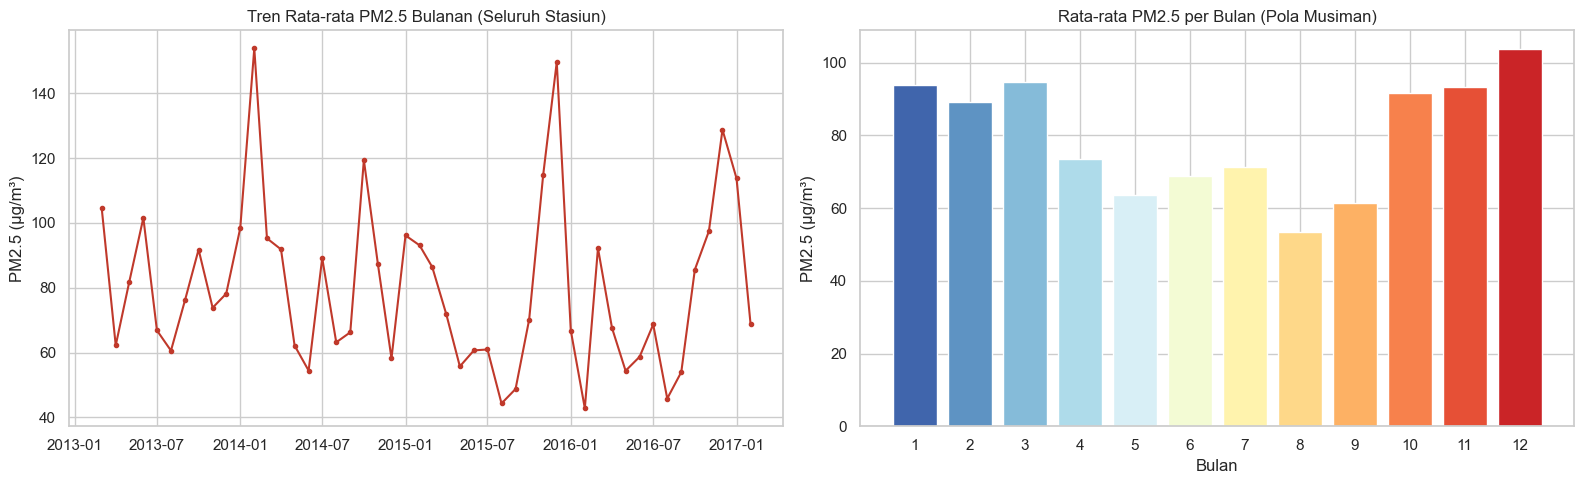

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

monthly_ts = df.set_index("datetime")["PM2.5"].resample("MS").mean()
axes[0].plot(monthly_ts.index, monthly_ts.values, color="#c0392b", marker="o", markersize=3)
axes[0].set_title("Tren Rata-rata PM2.5 Bulanan (Seluruh Stasiun)")
axes[0].set_xlabel(None); axes[0].set_ylabel("PM2.5 (µg/m³)")

axes[1].bar(monthly_pm.index, monthly_pm.values, color=sns.color_palette("RdYlBu_r", 12))
axes[1].set_xticks(range(1, 13))
axes[1].set_title("Rata-rata PM2.5 per Bulan (Pola Musiman)")
axes[1].set_xlabel("Bulan"); axes[1].set_ylabel("PM2.5 (µg/m³)")

plt.tight_layout(); plt.show()

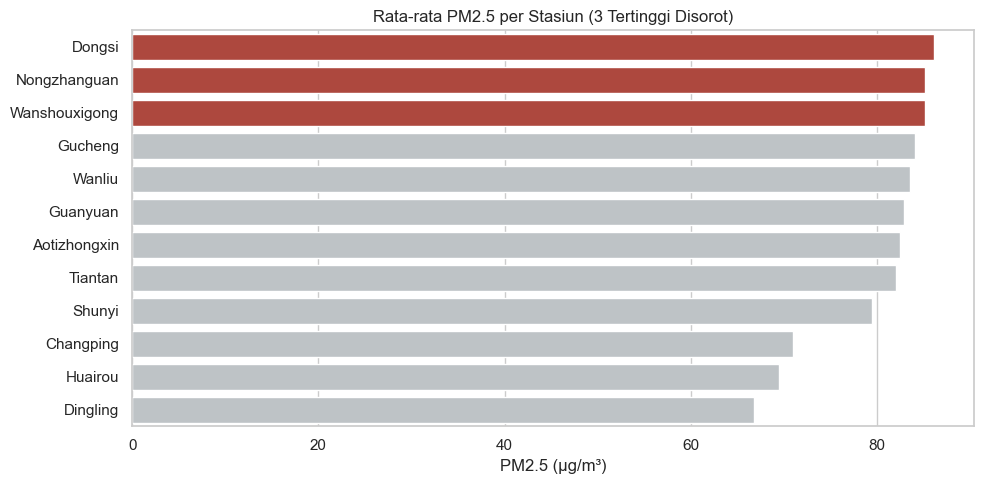

In [14]:
fig, ax = plt.subplots(figsize=(10, 5))
order = station_pm.index
colors = ["#c0392b" if i < 3 else "#bdc3c7" for i in range(len(order))]
sns.barplot(x=station_pm["mean"], y=order, palette=colors, hue=order, legend=False, ax=ax)
ax.set_title("Rata-rata PM2.5 per Stasiun (3 Tertinggi Disorot)")
ax.set_xlabel("PM2.5 (µg/m³)"); ax.set_ylabel(None)
plt.tight_layout(); plt.show()

**Insight:**
- Tidak ada penurunan yang konsisten sepanjang periode: PM2.5 sempat turun di 2016, lalu naik lagi pada data awal 2017 (hanya Jan–Feb, yaitu musim dingin).
- Puncak polusi terjadi di musim dingin (Desember tertinggi, ~104 µg/m³) dan terendah di Agustus (~54 µg/m³). Kenaikan juga terlihat sejak Oktober.
- Selisih antar stasiun cukup besar (sekitar 67 vs 86 µg/m³): area pinggiran lebih bersih daripada pusat kota.

### Pertanyaan 2: Faktor cuaca apa yang paling berkaitan dengan PM2.5?

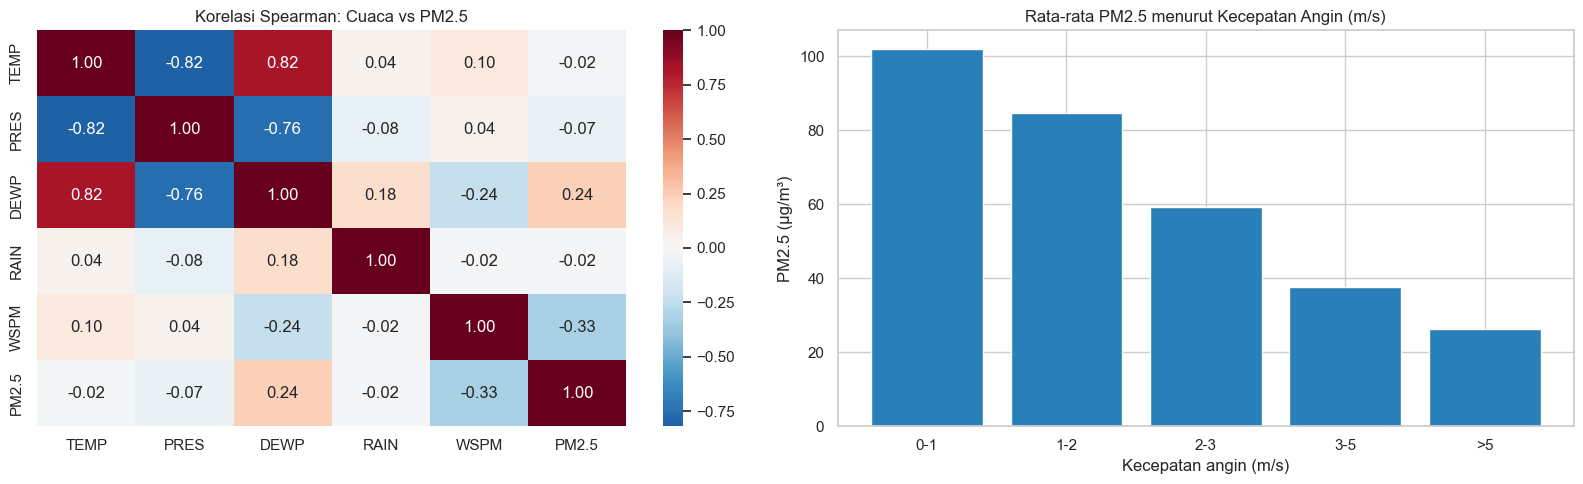

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

sns.heatmap(df[weather_cols + ["PM2.5"]].corr(method="spearman"), annot=True, fmt=".2f",
            cmap="RdBu_r", center=0, ax=axes[0])
axes[0].set_title("Korelasi Spearman: Cuaca vs PM2.5")

wind_pm = df.groupby("wind_bin", observed=True)["PM2.5"].mean()
axes[1].bar(wind_pm.index.astype(str), wind_pm.values, color="#2980b9")
axes[1].set_title("Rata-rata PM2.5 menurut Kecepatan Angin (m/s)")
axes[1].set_xlabel("Kecepatan angin (m/s)"); axes[1].set_ylabel("PM2.5 (µg/m³)")

plt.tight_layout(); plt.show()

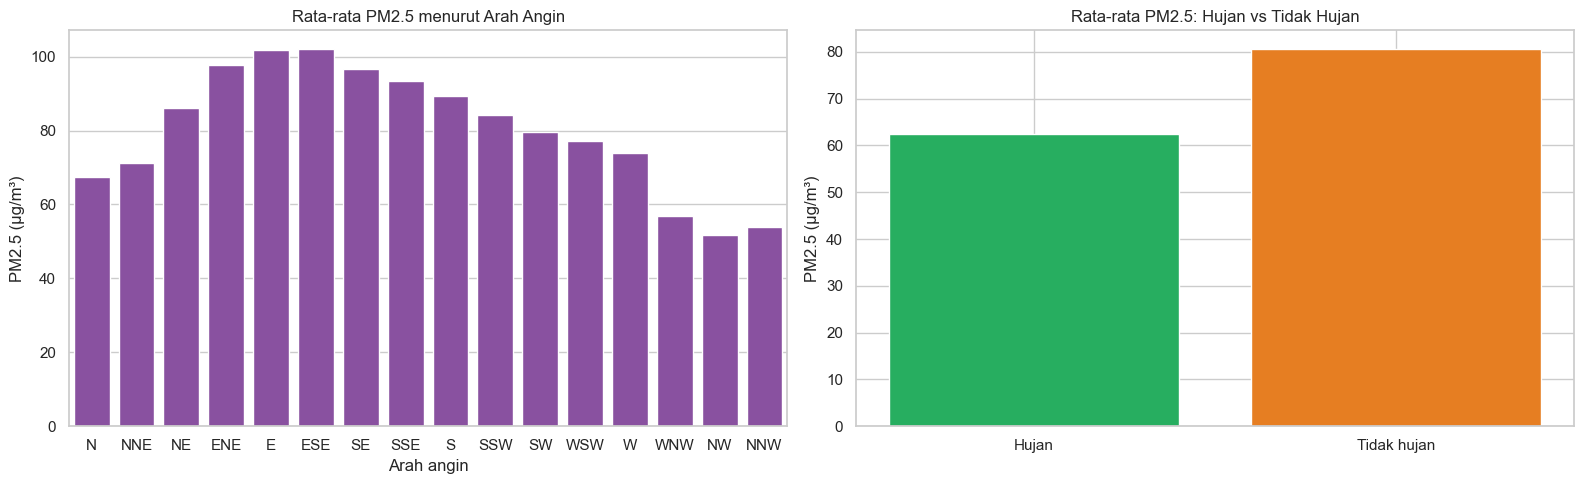

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

wd_order = ["N", "NNE", "NE", "ENE", "E", "ESE", "SE", "SSE", "S", "SSW", "SW", "WSW", "W", "WNW", "NW", "NNW"]
wd_pm = df.groupby("wd")["PM2.5"].mean().reindex(wd_order)
sns.barplot(x=wd_pm.index, y=wd_pm.values, color="#8e44ad", ax=axes[0])
axes[0].set_title("Rata-rata PM2.5 menurut Arah Angin")
axes[0].set_xlabel("Arah angin"); axes[0].set_ylabel("PM2.5 (µg/m³)")

rain_pm = df.groupby("rain_status")["PM2.5"].mean()
axes[1].bar(rain_pm.index, rain_pm.values, color=["#27ae60", "#e67e22"])
axes[1].set_title("Rata-rata PM2.5: Hujan vs Tidak Hujan")
axes[1].set_ylabel("PM2.5 (µg/m³)")

plt.tight_layout(); plt.show()

**Insight:**
- Kecepatan angin adalah faktor yang paling jelas: makin kencang angin, makin rendah PM2.5.
- PM2.5 turun tajam seiring kecepatan angin: ~102 µg/m³ pada angin 0–1 m/s menjadi ~26 µg/m³ pada angin >5 m/s.
- Titik embun yang tinggi (udara lembap) berkaitan dengan PM2.5 lebih tinggi; suhu dan tekanan hampir tidak berkorelasi linear.
- Angin dari timur–tenggara (ESE, E, ENE, SE) membawa PM2.5 tertinggi (~97–102), sedangkan angin dari barat laut (NW, NNW, WNW) paling bersih (~52–57).
- Hari hujan lebih bersih daripada tidak hujan, tetapi pengaruhnya lebih kecil dibanding angin.

## Analisis Lanjutan (Opsional): Binning Kategori Kualitas Udara

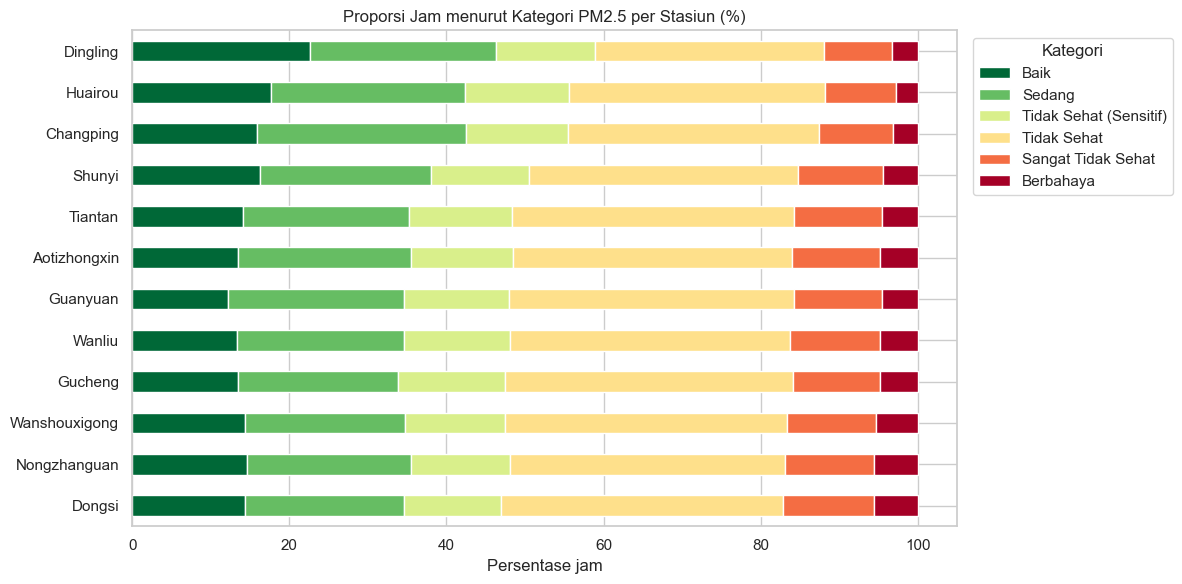

In [17]:
cat_station = pd.crosstab(df["station"], df["pm25_category"], normalize="index") * 100
cat_station = cat_station.loc[station_pm.index]

cat_station.plot(kind="barh", stacked=True, figsize=(12, 6), colormap="RdYlGn_r")
plt.title("Proporsi Jam menurut Kategori PM2.5 per Stasiun (%)")
plt.xlabel("Persentase jam"); plt.ylabel(None)
plt.legend(title="Kategori", bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout(); plt.show()

**Insight:**
- Secara keseluruhan hanya ~15% jam masuk kategori "Baik" (PM2.5 ≤ 12 µg/m³), sedangkan ~50% jam berada di kategori "Tidak Sehat (Sensitif)" atau lebih buruk.
- Porsi jam "Tidak Sehat (Sensitif)" atau lebih buruk terendah di Dingling (~41%) dan tertinggi di Dongsi (~53%).

## Menyimpan Data untuk Dashboard

In [18]:
# Agregasi harian per stasiun agar ukuran file ringan untuk dashboard
daily = (
    df.assign(date=df["datetime"].dt.floor("D"))
    .groupby(["date", "station"])
    .agg(PM25=("PM2.5", "mean"), PM10=("PM10", "mean"), SO2=("SO2", "mean"), NO2=("NO2", "mean"),
         CO=("CO", "mean"), O3=("O3", "mean"), TEMP=("TEMP", "mean"), PRES=("PRES", "mean"),
         DEWP=("DEWP", "mean"), RAIN=("RAIN", "sum"), WSPM=("WSPM", "mean"),
         wd=("wd", lambda s: s.mode().iloc[0]))
    .reset_index()
)
daily["year"] = daily["date"].dt.year
daily["month"] = daily["date"].dt.month
daily["season"] = daily["month"].map(season_map)
daily["pm25_category"] = pd.cut(daily["PM25"], bins=bins, labels=labels).astype(str)
daily = daily.round(2)

daily.to_csv("dashboard/main_data.csv", index=False)
print(daily.shape)
daily.head()

(17532, 18)


,date,station,PM25,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,WSPM,wd,year,month,season,pm25_category
0,2013-03-01,Aotizhongxin,7.12,10.75,11.71,22.58,429.17,63.88,1.39,1026.88,-18.75,0.0,3.25,N,2013,3,Semi,Baik
1,2013-03-01,Changping,5.08,18.96,16.04,15.33,387.50,77.79,0.81,1023.86,-19.58,0.0,2.13,N,2013,3,Semi,Baik
2,2013-03-01,Dingling,6.38,6.27,3.00,2.29,204.17,81.96,0.81,1023.86,-19.58,0.0,2.13,N,2013,3,Semi,Baik
3,2013-03-01,Dongsi,6.42,9.88,8.29,28.23,389.58,72.75,1.32,1028.78,-21.47,0.0,3.31,NNW,2013,3,Semi,Baik
4,2013-03-01,Guanyuan,7.54,11.67,8.50,28.50,400.00,63.17,1.39,1026.88,-18.75,0.0,3.25,N,2013,3,Semi,Baik


## Conclusion

- **Pertanyaan 1:** PM2.5 Beijing tidak menunjukkan penurunan yang konsisten pada 2013–2017, tetapi punya pola musiman kuat: tertinggi di musim dingin (Desember puncaknya) dan terendah di musim panas (Agustus terendah). Stasiun paling tercemar adalah Dongsi, Wanshouxigong, dan Nongzhanguan (area perkotaan), sedangkan Dingling dan Huairou paling bersih.
- **Pertanyaan 2:** Kecepatan angin adalah faktor cuaca yang paling berpengaruh (angin kencang menurunkan PM2.5). Titik embun yang tinggi berkaitan dengan PM2.5 lebih tinggi, hujan membantu menurunkan konsentrasi, dan arah angin menentukan asal massa udara: dari timur–tenggara lebih kotor, dari barat laut lebih bersih. Suhu dan tekanan hampir tidak berkorelasi linear.
- Korelasi tidak sama dengan sebab-akibat; faktor emisi (pemanas musim dingin, lalu lintas, industri) juga berperan.